In [1]:
# package import
import numpy as np
from numpy import arange
import pandas as pd
from pandas import read_csv
from pandas import set_option
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error


In [2]:
# loading data
X_train_data = pd.read_csv("X_train_processed_61.csv")
y_train_data = pd.read_csv("y_train.csv")

X_train = X_train_data.values
y_train = y_train_data.values.ravel()

In [3]:
import json

In [4]:
with open("column_names.json", "w") as f:
    json.dump(list(X_train_data.columns), f, indent=2)

In [5]:
# starting model:
# healthcare_system_confidence, -government_covid_response, -i11_health
# -perceived_covid_severity, -age, -avoiding_infected_people
# -hand_sanitizer_frequency
# -i12_health_13, -i12_health_22, -i12_health_25

starting_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
    "ord__hand_sanitizer_frequency",
    "ord__i12_health_13",
    "ord__i12_health_22",
    "ord__i12_health_25",
]

In [6]:
# expanded model
# starting model + perceived_infection_risk + employment_status

expanded_cols = starting_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]

In [7]:
# compact model
# starting model - last four variables

compact_cols = [
    "cat__healthcare_system_confidence_A fair amount of confidence",
    "cat__healthcare_system_confidence_A lot of confidence",
    "cat__healthcare_system_confidence_Don't know",
    "cat__healthcare_system_confidence_No confidence at all",
    "cat__healthcare_system_confidence_Not very much confidence",
    "cat__government_covid_response_Don't know",
    "cat__government_covid_response_Somewhat badly",
    "cat__government_covid_response_Somewhat well",
    "cat__government_covid_response_Very badly",
    "cat__government_covid_response_Very well",
    "ord__i11_health",
    "ord__perceived_covid_severity",
    "num__age",
    "ord__avoiding_infected_people",
]

In [24]:
compact_plus_cols = compact_cols + [
    "ord__perceived_infection_risk",
    "cat__employment_status_Full time employment",
    "cat__employment_status_Full time student",
    "cat__employment_status_Not working",
    "cat__employment_status_Other",
    "cat__employment_status_Part time employment",
    "cat__employment_status_Retired",
    "cat__employment_status_Unemployed",
]


In [27]:
X_train_starting = X_train_data[starting_cols].values
X_train_expanded = X_train_data[expanded_cols].values
X_train_compact = X_train_data[compact_cols].values
X_train_compact_plus = X_train_data[compact_plus_cols].values

In [28]:
feature_sets = {
    "all_61": X_train,
    "starting_model": X_train_starting,
    "expanded_model": X_train_expanded,
    "compact_model": X_train_compact,
    "compact_plus_model": X_train_compact_plus,
}

In [20]:
num_folds = 10
seed = 42
scoring = 'neg_mean_squared_error'
model = KNeighborsClassifier()
kfold = StratifiedKFold(n_splits=num_folds, random_state=seed, shuffle=True)

weight_model = KNeighborsClassifier(weights='distance', metric="manhattan")


In [29]:
# check for each model

# different k values list to try
# k_values = [3, 5, 7, 9, 11, 21, 31, 41, 51, 61, 71]
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
param_grid = dict(n_neighbors=k_values)
all_cv_mse = {}
all_stds = {}
all_params = {}

w_all_cv_mse = {}
w_all_stds = {}
w_all_params = {}

for name, X_sub in feature_sets.items():
    # scale this model's columns
    scaler = StandardScaler().fit(X_sub)
    rescaledX = scaler.transform(X_sub)

    # try every k with 10-fold CV
    grid = GridSearchCV(estimator=model, param_grid=param_grid,
                        scoring=scoring, cv=kfold)
    grid_result = grid.fit(rescaledX, y_train)

    # try every k with weighted model

    w_grid = GridSearchCV(estimator=weight_model, param_grid=param_grid,
                        scoring=scoring, cv=kfold)
    w_grid_result = w_grid.fit(rescaledX, y_train)

    print("=== %s ===" % name)
    print("Best: %f using K = %s" % ((-1)*grid_result.best_score_, int(grid_result.best_params_['n_neighbors'])))

    print("=== weighted %s ===" % name)
    print("Best: %f using K = %s" % ((-1)*w_grid_result.best_score_, int(w_grid_result.best_params_['n_neighbors'])))

    cv_mse = (-1)*grid_result.cv_results_['mean_test_score']
    cv_stds = grid_result.cv_results_['std_test_score']
    cv_params = grid_result.cv_results_['params']

    all_cv_mse[name] = cv_mse 
    all_stds[name] = cv_stds
    all_params[name] = cv_params

    w_cv_mse = (-1)*w_grid_result.cv_results_['mean_test_score']
    w_cv_stds = w_grid_result.cv_results_['std_test_score']
    w_cv_params = w_grid_result.cv_results_['params']

    w_all_cv_mse[name] = w_cv_mse
    w_all_stds[name] = w_cv_stds
    w_all_params[name] = w_cv_params


=== all_61 ===
Best: 0.230950 using K = 9
=== weighted all_61 ===
Best: 0.213644 using K = 7
=== starting_model ===
Best: 0.220246 using K = 15
=== weighted starting_model ===
Best: 0.227052 using K = 25
=== expanded_model ===
Best: 0.224724 using K = 21
=== weighted expanded_model ===
Best: 0.214038 using K = 17
=== compact_model ===
Best: 0.220052 using K = 21
=== weighted compact_model ===
Best: 0.234245 using K = 25
=== compact_plus_model ===
Best: 0.222583 using K = 21
=== weighted compact_plus_model ===
Best: 0.217142 using K = 25


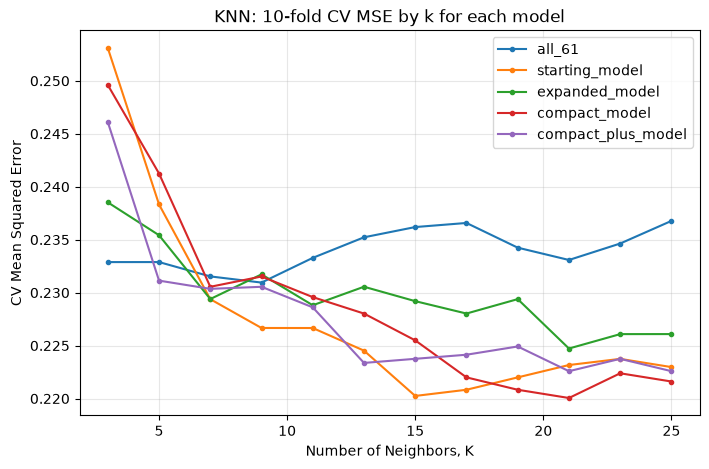

In [30]:
# plot K vs cv_mse

plt.figure(figsize=(8, 5))
for name, cv_mse in all_cv_mse.items():
    plt.plot(k_values, cv_mse, marker='o', markersize=3, label=name)

plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Mean Squared Error")
plt.title("KNN: 10-fold CV MSE by k for each model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



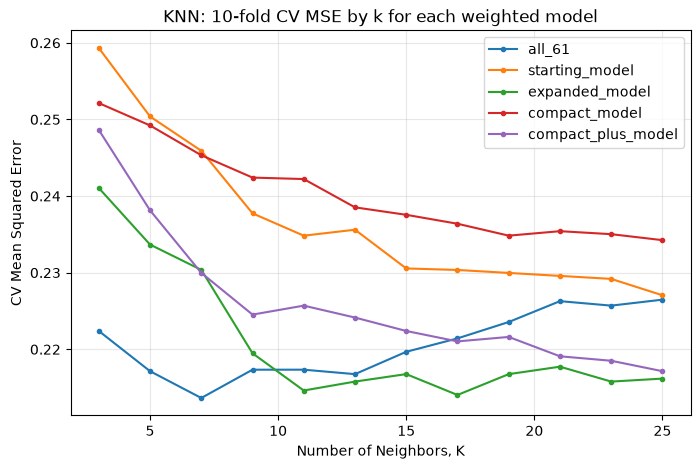

In [32]:
# plot K vs w_cv_mse for weighted model

plt.figure(figsize=(8, 5))
for name, w_cv_mse in w_all_cv_mse.items():
    plt.plot(k_values, w_cv_mse, marker='o', markersize=3, label=name)

plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Mean Squared Error")
plt.title("KNN: 10-fold CV MSE by k for each weighted model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



In [42]:
bal_scoring = 'balanced_accuracy'

all_cv_balacc = {}
all_stds_balacc = {}

w_all_cv_balacc = {}
w_all_stds_balacc = {}

for name, X_sub in feature_sets.items():
    scaler = StandardScaler().fit(X_sub)
    rescaledX = scaler.transform(X_sub)

    bal_grid = GridSearchCV(estimator=model, param_grid=param_grid,
                        scoring=bal_scoring, cv=kfold)
    bal_grid_result = bal_grid.fit(rescaledX, y_train)

    w_bal_grid = GridSearchCV(estimator=weight_model, param_grid=param_grid,
                            scoring=bal_scoring, cv=kfold)
    w_bal_grid_result = w_bal_grid.fit(rescaledX, y_train)

    print("=== %s ===" % name)
    print("Best balanced accuracy: %f using K = %d" %
          (bal_grid_result.best_score_, bal_grid_result.best_params_['n_neighbors']))

    print("=== weighted %s ===" % name)
    print("Best balanced accuracy: %f using K = %d" %
              (w_bal_grid_result.best_score_, w_bal_grid_result.best_params_['n_neighbors']))

    all_cv_balacc[name] = bal_grid_result.cv_results_['mean_test_score']
    all_stds_balacc[name]      = bal_grid_result.cv_results_['std_test_score']
    w_all_cv_balacc[name] = w_bal_grid_result.cv_results_['mean_test_score']
    w_all_stds_balacc[name] = w_bal_grid_result.cv_results_['std_test_score']

=== all_61 ===
Best balanced accuracy: 0.675828 using K = 3
=== weighted all_61 ===
Best balanced accuracy: 0.688295 using K = 3
=== starting_model ===
Best balanced accuracy: 0.681378 using K = 7
=== weighted starting_model ===
Best balanced accuracy: 0.679435 using K = 11
=== expanded_model ===
Best balanced accuracy: 0.680317 using K = 3
=== weighted expanded_model ===
Best balanced accuracy: 0.693329 using K = 11
=== compact_model ===
Best balanced accuracy: 0.678931 using K = 7
=== weighted compact_model ===
Best balanced accuracy: 0.679207 using K = 19
=== compact_plus_model ===
Best balanced accuracy: 0.680956 using K = 5
=== weighted compact_plus_model ===
Best balanced accuracy: 0.692165 using K = 9


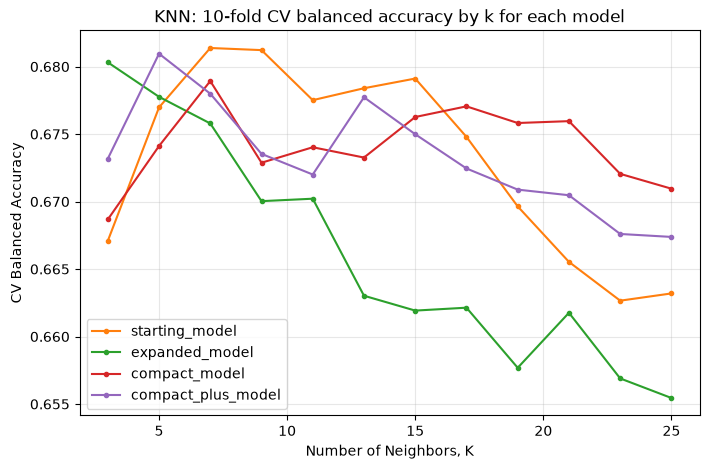

In [43]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3", "compact_plus_model": "C4"}

plt.figure(figsize=(8, 5))
for name, score in all_cv_balacc.items():
    if name == "all_61":
        continue   
    plt.plot(k_values, score, marker='o', markersize=3, label=name, color=colors[name])
plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Balanced Accuracy")
plt.title("KNN: 10-fold CV balanced accuracy by k for each model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

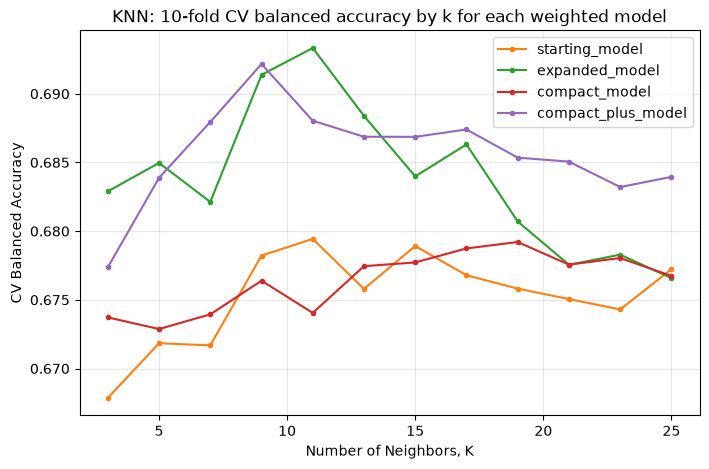

In [47]:
colors = {"all_61": "C0", "starting_model": "C1",
          "expanded_model": "C2", "compact_model": "C3", "compact_plus_model": "C4"}

plt.figure(figsize=(8, 5))
for name, score in w_all_cv_balacc.items():
    if name == "all_61":
        continue   
    plt.plot(k_values, score, marker='o', markersize=3, label=name, color=colors[name])
plt.xlabel("Number of Neighbors, K")
plt.ylabel("CV Balanced Accuracy")
plt.title("KNN: 10-fold CV balanced accuracy by k for each weighted model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()